In [5]:
  # Import necessary libraries
import torch
import torch.nn as nn
import torch.optim as optim
from torchvision import datasets, models, transforms
from torch.utils.data import DataLoader, random_split
from sklearn.metrics import confusion_matrix, precision_score, recall_score, f1_score
import matplotlib.pyplot as plt
import time
import numpy as np
from google.colab import drive

In [6]:
# Mount Google Drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [7]:
# Define the KYC dataset paths
zip_path = "/content/KYC DATASET.zip"
extract_path = "/content/KYC_DATASET"

print("ZIP exists:", os.path.exists(zip_path))

ZIP exists: True


In [8]:
num_classes = 2
batch_size = 16
num_epochs = 15
learning_rate = 0.0001

In [9]:
# Data transformations
data_transforms = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        [0.485, 0.456, 0.406],
        [0.229, 0.224, 0.225]
    )
])

In [13]:
import os
import zipfile

zip_path = "/content/KYC DATASET.zip"
extract_path = "/content/KYC_DATASET"

# Extract the ZIP
with zipfile.ZipFile(zip_path, "r") as zip_ref:
    zip_ref.extractall(extract_path)

# Find the class folders (case-insensitive)
data_dir = None

for root, dirs, files in os.walk(extract_path):
    folder_names = {d.lower(): d for d in dirs}

    if "fake" in folder_names and "original" in folder_names:
        data_dir = root
        break

print("Dataset path:", data_dir)

if data_dir is None:
    raise FileNotFoundError(
        "Could not find both Fake and Original folders."
    )

Dataset path: /content/KYC_DATASET/KYC DATASET


In [15]:
# Load KYC dataset
dataset = datasets.ImageFolder(
    root=data_dir,
    transform=data_transforms
)

print("Classes:", dataset.classes)
print("Class mapping:", dataset.class_to_idx)
print("Total images:", len(dataset))

assert dataset.classes == ["Fake", "Original"], (
    "Check your folder names and dataset path."
)

Classes: ['Fake', 'Original']
Class mapping: {'Fake': 0, 'Original': 1}
Total images: 200


In [16]:
# Split the dataset: 80% training, 20% validation
train_size = int(0.8 * len(dataset))
val_size = len(dataset) - train_size

train_dataset, val_dataset = random_split(
    dataset,
    [train_size, val_size],
    generator=torch.Generator().manual_seed(42)
)

print("Training images:", len(train_dataset))
print("Validation images:", len(val_dataset))

Training images: 160
Validation images: 40


In [17]:
batch_size = 16

train_loader = DataLoader(
    train_dataset,
    batch_size=batch_size,
    shuffle=True,
    num_workers=2
)

val_loader = DataLoader(
    val_dataset,
    batch_size=batch_size,
    shuffle=False,
    num_workers=2
)

In [18]:
# Load the VGG16 model
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
model = models.vgg16(pretrained=True)

/usr/local/lib/python3.13/dist-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=VGG16_Weights.IMAGENET1K_V1`. You can also use `weights=VGG16_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)


In [19]:
# Freeze feature extractor layers
for param in model.features.parameters():
    param.requires_grad = False

In [20]:
# Modify the classifier
model.classifier[6] = nn.Linear(model.classifier[6].in_features, num_classes)
model = model.to(device)
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.classifier.parameters(), lr=learning_rate)

In [21]:
# Variables
train_accuracies, val_accuracies = [], []
train_losses, val_losses = [], []
epoch_times = []

In [22]:
for epoch in range(num_epochs):

    start_time = time.time()

    # Training
    model.train()
    running_loss = 0.0
    all_preds = []
    all_labels = []

    for inputs, labels in train_loader:

        inputs, labels = inputs.to(device), labels.to(device)

        optimizer.zero_grad()

        outputs = model(inputs)

        loss = criterion(outputs, labels)

        loss.backward()

        optimizer.step()

        running_loss += loss.item() * inputs.size(0)

        _, preds = torch.max(outputs, 1)

        all_preds.extend(preds.cpu().numpy())
        all_labels.extend(labels.cpu().numpy())

    epoch_loss = running_loss / len(train_loader.dataset)

    train_losses.append(epoch_loss)

    train_accuracy = np.mean(np.array(all_preds) == np.array(all_labels))

    train_accuracies.append(train_accuracy)


    # Validation
    model.eval()

    val_loss = 0.0
    all_preds = []
    all_labels = []

    with torch.no_grad():

        for inputs, labels in val_loader:

            inputs, labels = inputs.to(device), labels.to(device)

            outputs = model(inputs)

            loss = criterion(outputs, labels)

            val_loss += loss.item() * inputs.size(0)

            _, preds = torch.max(outputs, 1)

            all_preds.extend(preds.cpu().numpy())
            all_labels.extend(labels.cpu().numpy())

    val_loss /= len(val_loader.dataset)

    val_losses.append(val_loss)

    val_accuracy = np.mean(np.array(all_preds) == np.array(all_labels))

    val_accuracies.append(val_accuracy)


    epoch_time = time.time() - start_time

    epoch_times.append(epoch_time)


    print(f"Epoch {epoch+1}/{num_epochs}")





Epoch 1/15
Epoch 2/15
Epoch 3/15
Epoch 4/15
Epoch 5/15
Epoch 6/15
Epoch 7/15
Epoch 8/15
Epoch 9/15
Epoch 10/15
Epoch 11/15
Epoch 12/15
Epoch 13/15
Epoch 14/15
Epoch 15/15


In [23]:
# Training and validation loop
print(len(train_accuracies))
print(len(val_accuracies))


15
15


In [24]:
# Metrics Calculation
precision = precision_score(all_labels, all_preds, average='binary')
recall = recall_score(all_labels, all_preds, average='binary')
f1 = f1_score(all_labels, all_preds, average='binary')



/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


In [25]:
# Confusion Matrix and Specificity
cm = confusion_matrix(all_labels, all_preds)
tn, fp, fn, tp = cm.ravel()
specificity = tn / (tn + fp)

epoch_time = time.time() - start_time
epoch_times.append(epoch_time)

train_accuracies.append(train_accuracy)
val_accuracies.append(val_accuracy)



print(f"Epoch {epoch+1}/{num_epochs}, Train Loss: {epoch_loss:.4f}, Train Accuracy: {train_accuracy:.4f}")
print(f"Validation Loss: {val_loss:.4f}, Validation Accuracy: {val_accuracy:.4f}")
print(f"Precision: {precision:.4f}, Recall: {recall:.4f}, F1 Score: {f1:.4f}, Specificity: {specificity:.4f}")
print(f"Confusion Matrix:\n{cm}")
print(f"Epoch Runtime: {epoch_time:.2f} seconds\n")


Epoch 15/15, Train Loss: 0.6976, Train Accuracy: 0.5938
Validation Loss: 0.8163, Validation Accuracy: 0.4750
Precision: 0.0000, Recall: 0.0000, F1 Score: 0.0000, Specificity: 1.0000
Confusion Matrix:
[[19  0]
 [21  0]]
Epoch Runtime: 176.54 seconds



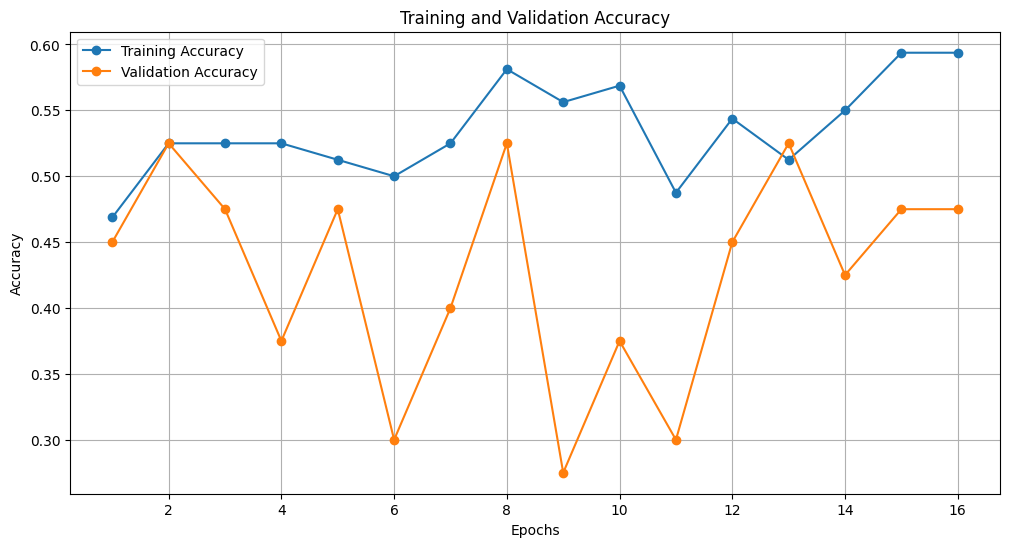

In [26]:
# Plotting Accuracy
plt.figure(figsize=(12,6))

plt.plot(range(1, len(train_accuracies)+1),
         train_accuracies,
         label='Training Accuracy',
         marker='o')

plt.plot(range(1, len(val_accuracies)+1),
         val_accuracies,
         label='Validation Accuracy',
         marker='o')

plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.title('Training and Validation Accuracy')

plt.legend()
plt.grid()

plt.show()



In [27]:
torch.save(
    model.state_dict(),
    "/content/drive/MyDrive/kyc_vgg16_model.pth"
)

In [28]:
from PIL import Image
import torch
import torch.nn.functional as F
import os

# Save/load the KYC VGG16 model
model_path = "/content/drive/MyDrive/kyc_vgg16_model.pth"

# Load the saved KYC model
model.load_state_dict(
    torch.load(model_path, map_location=device)
)

model.eval()

# Select an image from the KYC dataset
fake_folder = os.path.join(data_dir, dataset.classes[0])

image_files = [
    f for f in os.listdir(fake_folder)
    if f.lower().endswith((".jpg", ".jpeg", ".png", ".webp"))
]

if not image_files:
    raise FileNotFoundError("No images found in the fake folder.")

image_path = os.path.join(fake_folder, image_files[0])

# Image transformation
transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        [0.485, 0.456, 0.406],
        [0.229, 0.224, 0.225]
    )
])

# Load image
image = Image.open(image_path).convert("RGB")
image = transform(image).unsqueeze(0).to(device)

# Prediction
with torch.no_grad():
    outputs = model(image)
    probs = F.softmax(outputs, dim=1)
    predicted = torch.argmax(probs, dim=1).item()

# Display result
classes = dataset.classes

print("Image:", image_path)
print("Predicted class:", classes[predicted])
print("Confidence:", round(probs[0, predicted].item() * 100, 2), "%")

Prediction : Original
Confidence : 0.538113534450531


In [30]:
import os
from PIL import Image
import torch.nn.functional as F

# Choose folder you want to test
# yes = Fake images
# no = Real images

test_folder = os.path.join(data_dir, "Fake")

model.eval()

print("Checking Images...\n")

for file in os.listdir(test_folder):

    if file.endswith((".jpg",".png",".jpeg")):

        image_path = os.path.join(test_folder, file)

        image = Image.open(image_path).convert("RGB")

        image = transform(image).unsqueeze(0).to(device)

        with torch.no_grad():

            outputs = model(image)

            probs = F.softmax(outputs, dim=1)

            _, predicted = torch.max(outputs,1)

        print("Image :", file)
        print("Prediction :", dataset.classes[predicted.item()])
        print("Confidence :", probs.max().item())
        print("--------------------------")


Checking Images...

Image : 51.jpg
Prediction : Fake
Confidence : 0.6272577047348022
--------------------------
Image : 22.jpg
Prediction : Fake
Confidence : 0.6461508870124817
--------------------------
Image : 64.jpg
Prediction : Fake
Confidence : 0.7329722046852112
--------------------------
Image : 08.jpg
Prediction : Fake
Confidence : 0.6333787441253662
--------------------------
Image : 55.jpg
Prediction : Fake
Confidence : 0.6712274551391602
--------------------------
Image : 04.jpg
Prediction : Fake
Confidence : 0.6725192070007324
--------------------------
Image : 36.jpg
Prediction : Fake
Confidence : 0.7146893739700317
--------------------------
Image : 03.jpg
Prediction : Fake
Confidence : 0.5879730582237244
--------------------------
Image : 98.jpg
Prediction : Fake
Confidence : 0.6367871761322021
--------------------------
Image : 68.jpg
Prediction : Fake
Confidence : 0.7560659646987915
--------------------------
Image : 00.jpg
Prediction : Fake
Confidence : 0.589043438434